# Experiment 1 — 1D Gaussian

Train DQGM on a discretised 1D Gaussian, then compare the learned density to
the target and look at the KL / TVD curves.

This notebook the uses configuration in `configs/exp1_gaussian.yaml`.

In [5]:
import os, csv, yaml
# By default JAX preallocates ~75% of every visible GPU's memory. On a shared
# multi-GPU node, several open notebook kernels then exhaust the GPUs. Allocate
# on demand instead. (Must be set before `import jax`.)
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')
# os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')  # pin to one GPU
import jax
import numpy as np
import matplotlib.pyplot as plt

from dqgm import Model, Dataset, ClassicalSimulator, QiskitSimulator, Trainer, Logger
from dqgm import counts_to_probabilities

# On a GPU machine this should print CudaDevice(...). CpuDevice means the
# kernel is not the `dqgm` env and training will be much slower.
print('JAX devices:', jax.devices())

cfg = yaml.safe_load(open('../configs/exp1_gaussian.yaml'))
# Short demo run (~30 s on GPU). The Gaussian converges quickly; set
# num_steps back to 10000 to reproduce the paper result.
cfg['training']['num_steps'] = 10000
cfg['training']['checkpoint_every'] = 1000     # how often KL/TVD are evaluated
cfg['experiment']['save_dir'] = './logs/exp1_gaussian/'
nprec = cfg['model']['num_visible_per_feature'] - cfg['model']['freq_buffer']

JAX devices: [CudaDevice(id=0), CudaDevice(id=1), CudaDevice(id=2), CudaDevice(id=3)]


In [6]:
ds = Dataset(**cfg['data'])
X = ds.dataloader(num_feature=cfg['model']['num_feature'],
                  num_precision=nprec,
                  multivariate_bits=cfg['model']['multivariate_bits'])
target = ds.get_distribution(num_feature=cfg['model']['num_feature'], num_precision=nprec)

model = Model(**cfg['model'])
model.init_parameters(config_data=cfg['data'], X_train=X)

sim = ClassicalSimulator(model, **cfg['classical_simulator'])
sampler = QiskitSimulator(model)
logger = Logger(cfg['experiment']['save_dir'])

# The first training step is slow (~10 s) because JAX JIT-compiles the
# update; every step after that is fast.
trainer = Trainer(model, sim, sampler, **cfg['training'])
trainer.train(X, target, cfg['model'], logger)

Training: 100%|██████████| 10000/10000 [03:30<00:00, 47.43it/s, Loss=10.273, KL=0.006, TVD=0.021]


## Learned vs. target density

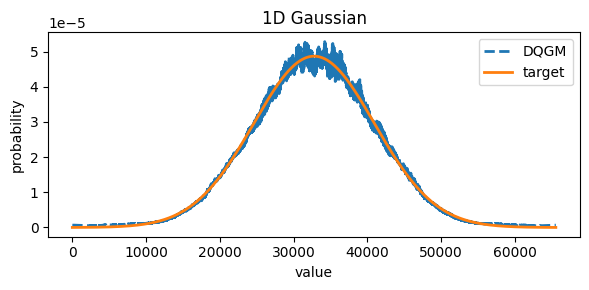

In [9]:
probs = counts_to_probabilities(
    sampler.exact_output_probabilities(model.params),
    model.num_feature, model.readout_size,
).flatten()

x = np.arange(probs.size)
plt.figure(figsize=(6, 3))
plt.plot(x, probs, label='DQGM', lw=2, ls='--')
plt.plot(x, target, label='target', lw=2)
plt.xlabel('value'); plt.ylabel('probability'); plt.legend()
plt.title('1D Gaussian'); plt.tight_layout(); plt.show()

## Training curves

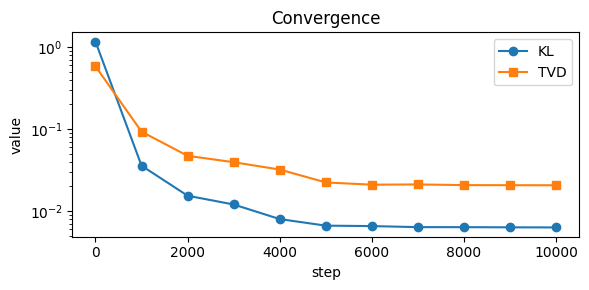

In [10]:
rows = list(csv.DictReader(open(os.path.join(logger.log_dir, 'history.csv'))))
steps = np.array([float(r['step']) for r in rows])
kl = np.array([float(r['train_kl']) for r in rows])
td = np.array([float(r['train_tvd']) for r in rows])
ok = ~np.isnan(kl)  # KL/TVD are recorded only at checkpoint steps

plt.figure(figsize=(6, 3))
plt.plot(steps[ok], kl[ok], marker='o', label='KL')
plt.plot(steps[ok], td[ok], marker='s', label='TVD')
plt.yscale('log')
plt.xlabel('step'); plt.ylabel('value'); plt.legend()
plt.title('Convergence'); plt.tight_layout(); plt.show()